# Process Discovery Lab
### Abstraction with a simple LSTM generative model


# 2. Importing libraries

In [1]:
!pip install pm4py

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 2.7/2.7 MB 13.1 MB/s  0:00:00


In [2]:
import copy, os, random, time
from collections import Counter

import numpy as np
import pandas as pd
import pm4py
import torch
import torch.nn as nn
from pm4py.objects.log.obj import Event, EventLog, Trace

PAD, END = 0, 1  # END = simbolo di fine traccia (⊥)
print('pm4py', pm4py.__version__, '| torch', torch.__version__, '| cuda:', torch.cuda.is_available())



  Welcome to PM4Py — Community Version
  Open-Source License (AGPL v3)

  📚 Docs & Examples:
     https://processintelligence.solutions/pm4py

  ⚖️  License: AGPL v3 — Commercial use requires open-sourcing your application.
     Business use without open-sourcing? A commercial license is available:
     https://processintelligence.solutions/pm4py#licensing




pm4py 2.7.23.14 | torch 2.14.1+cu130 | cuda: True


# 3. Loading Data & Preprocessing



In [3]:
def load_traces(path):
    obj = pm4py.read_xes(path)
    df = obj if isinstance(obj, pd.DataFrame) else pm4py.convert_to_dataframe(obj)
    if "time:timestamp" in df.columns:
        df = df.sort_values(["case:concept:name", "time:timestamp"], kind="stable")
    grouped = df.groupby("case:concept:name", sort=False)["concept:name"]
    return [list(g) for _, g in grouped]


def collapse_self_loops(trace, max_rep=2):
    """Riduce ogni n-repetition (n>=2) a una 2-repetition (evita loop infiniti nell'LSTM)."""
    out, run = [], 0
    for i, a in enumerate(trace):
        run = run + 1 if i > 0 and a == trace[i - 1] else 1
        if run <= max_rep:
            out.append(a)
    return out


def pad_window(seq, W):
    seq = seq[-W:]
    return [PAD] * (W - len(seq)) + seq


def build_dataset(id_traces, W):
    """T_L: ogni prefisso (head) di lunghezza 1..|σ| con etichetta = attività successiva (END a fine traccia)."""
    X, y = [], []
    for t in id_traces:
        for k in range(1, len(t) + 1):
            X.append(pad_window(t[:k], W))
            y.append(t[k] if k < len(t) else END)
    return torch.tensor(X, dtype=torch.long), torch.tensor(y, dtype=torch.long)

# 4. Defining the generative model

In [4]:
class NextActivityLSTM(nn.Module):
    def __init__(self, n_cls, emb_dim=32, units=16):
        super().__init__()
        self.emb = nn.Embedding(n_cls, emb_dim, padding_idx=PAD)
        self.lstm = nn.LSTM(emb_dim, units, num_layers=2, batch_first=True)
        self.out = nn.Linear(units, n_cls)

    def forward(self, x):
        h, _ = self.lstm(self.emb(x))
        return self.out(h[:, -1])


from tqdm.auto import tqdm
from torch.utils.data import TensorDataset, DataLoader, random_split

def train_model(X, y, n_cls, lr, units, batch_size, device, max_epochs=200, patience=20, seed=0):
    g = torch.Generator().manual_seed(seed)
    torch.manual_seed(seed)

    # split 80/20 train/validation
    ds = TensorDataset(X, y)
    n_val = max(1, int(0.2 * len(ds)))
    train_ds, val_ds = random_split(ds, [len(ds) - n_val, n_val], generator=g)

    train_dl = DataLoader(train_ds, batch_size=batch_size, shuffle=True, generator=g)
    val_dl = DataLoader(val_ds, batch_size=4096, shuffle=False)

    model = NextActivityLSTM(n_cls, units=units).to(device)
    opt = torch.optim.NAdam(model.parameters(), lr=lr)
    loss_fn = nn.CrossEntropyLoss()

    best_loss, best_state, bad = float("inf"), None, 0
    pbar = tqdm(range(1, max_epochs + 1), desc="Training LSTM", unit="ep")
    for epoch in pbar:
        model.train()
        train_total = 0.0
        for xb, yb in train_dl:
            xb, yb = xb.to(device), yb.to(device)
            opt.zero_grad()
            loss = loss_fn(model(xb), yb)
            loss.backward()
            opt.step()
            train_total += loss.item() * len(xb)
        train_loss = train_total / len(train_ds)

        model.eval()
        val_total = 0.0
        with torch.no_grad():
            for xb, yb in val_dl:
                xb, yb = xb.to(device), yb.to(device)
                val_total += loss_fn(model(xb), yb).item() * len(xb)
        val_loss = val_total / len(val_ds)

        # --- early stopping ---
        if val_loss < best_loss - 1e-6:
            best_loss, best_state, bad = val_loss, copy.deepcopy(model.state_dict()), 0
        else:
            bad += 1

        pbar.set_postfix(train=f"{train_loss:.4f}", val=f"{val_loss:.4f}",
                         best=f"{best_loss:.4f}", patience=f"{bad}/{patience}")
        if bad >= patience:
            pbar.write(f"Early stopping all'epoca {epoch} (best val_loss={best_loss:.4f})")
            break

    model.load_state_dict(best_state)
    model.eval()
    return model, best_loss


# 5. Summary generation

In [5]:
@torch.no_grad()
def predict_next(model, prefix, W, device):
    x = torch.tensor([pad_window(prefix, W)], dtype=torch.long, device=device)
    return int(model(x).argmax(dim=1))


def generate_trace(model, seed_seq, W, max_len, device):
    """H*(σ): applica ripetutamente H finché predice END o si raggiunge max_len"""
    t = list(seed_seq)
    while len(t) < max_len:
        nxt = predict_next(model, t, W, device)
        if nxt == END:
            break
        t.append(nxt)
    return t


def choose_seed_length(id_traces):
    """l = lunghezza minima per cui esistono più di 1 seed distinti."""
    max_len = max(len(t) for t in id_traces)
    last = 1
    for l in range(1, max_len + 1):
        seeds = {tuple(t[:l]) for t in id_traces if len(t) >= l}
        if seeds:
            last = l
        if len(seeds) > 1:
            return l, sorted(seeds)
    return last, sorted({tuple(t[:last]) for t in id_traces if len(t) >= last})


def summarize_log(model, id_traces, W, device):
    max_len = max(len(t) for t in id_traces)
    l, seeds = choose_seed_length(id_traces)
    summary = []
    for s in seeds:
        tr = tuple(generate_trace(model, s, W, max_len, device))
        if tr not in summary:
            summary.append(tr)
    return l, summary

# 6. Iterative forward selection

In [6]:
def to_event_log(traces):
    log = EventLog()
    for i, t in enumerate(traces):
        tr = Trace()
        tr.attributes["concept:name"] = f"case_{i}"
        for a in t:
            tr.append(Event({"concept:name": a}))
        log.append(tr)
    return log


def discover(log, miner):
    """Discovery con filtri interni disattivati"""
    if miner == "inductive":
        return pm4py.discover_petri_net_inductive(log, noise_threshold=0.0)
    if miner == "ilp":
        return pm4py.discover_petri_net_ilp(log, alpha=1.0)
    raise ValueError(miner)


def quality(net, im, fm, orig_log):
    fit = pm4py.fitness_alignments(orig_log, net, im, fm)
    fit = fit.get("average_trace_fitness", fit.get("log_fitness"))  # cost-based fitness
    prec = pm4py.precision_alignments(orig_log, net, im, fm)       # ETC alignment-based
    f = 0.0 if fit + prec == 0 else 2 * fit * prec / (fit + prec)
    return fit, prec, f


def fmeasure_of(traces, orig_log, miner, cache):
    key = frozenset(traces)
    if key in cache:
        return cache[key]
    try:
        net, im, fm = discover(to_event_log(traces), miner)
        f = quality(net, im, fm, orig_log)[2]
    except Exception as e:  # modello non sound / replay fallito
        print("    (errore discovery/conformance:", type(e).__name__, ")")
        f = 0.0
    cache[key] = f
    return f


def forward_trace_selection(candidates, orig_log, miner):
    """Algoritmo 1: aggiunge greedy la traccia che massimizza la F-measure; si ferma se non migliora."""
    selected, remaining, best_f, cache = [], list(candidates), 0.0, {}
    while remaining:
        scored = [(fmeasure_of(selected + [c], orig_log, miner, cache), c) for c in remaining]
        f, c = max(scored, key=lambda x: x[0])
        if f <= best_f:
            break
        selected.append(c)
        remaining.remove(c)
        best_f = f
        print(f"  + aggiunta traccia ({len(selected)}), F-measure = {f:.3f}")
    return selected, best_f

# 7. Importing log

In [9]:
LOG_PATH = ("/content/aspera.xes")

MINER = 'inductive'      # 'inductive' |
WINDOW = 4              # W per padding+windowing
MAX_EPOCHS = 200
USE_SELECTION = True    # True = Iterative trace selection, False = baseline
OUT = 'abstraction'
SEED = 42

In [10]:
random.seed(SEED); np.random.seed(SEED); torch.manual_seed(SEED)
device = "cuda" if torch.cuda.is_available() else "cpu"
os.makedirs(OUT, exist_ok=True)
W = WINDOW

# 1. dati
raw = load_traces(LOG_PATH)
orig_log = to_event_log(raw)                      # log originale per la valutazione
traces = [collapse_self_loops(t) for t in raw]    # versione per l'LSTM
acts = sorted({a for t in traces for a in t})
act2id = {a: i + 2 for i, a in enumerate(acts)}
id2act = {i: a for a, i in act2id.items()}
id_traces = [[act2id[a] for a in t] for t in traces]
n_cls = len(acts) + 2
print(f"Tracce: {len(raw)} | attività: {len(acts)} | device: {device}")

# 2. T_L + training LSTM
t0 = time.time()
X, y = build_dataset(id_traces, W)
print(f"Labeled head sequence: {len(X)}")
model, val_loss = train_model(X, y, n_cls, lr=0.002, units=16, batch_size=128, device='cuda', max_epochs=200, patience=20, seed=0)

print(f"(val_loss={val_loss:.4f}) in {time.time() - t0:.0f}s")

/usr/local/lib/python3.13/dist-packages/pm4py/utils.py:1027: UserWarning: Install the optional requirement `r4pm` to import/export files faster. `rustxes` remains supported as a fallback.
  warnings.warn(


parsing log, completed traces ::   0%|          | 0/219 [00:00<?, ?it/s]

/usr/local/lib/python3.13/dist-packages/cudf/core/indexed_frame.py:3728: UserWarning: GPU-accelerated stable is currently not supported, defaulting to quicksort.
  warnings.warn(


Tracce: 219 | attività: 32 | device: cuda
Labeled head sequence: 3455


Training LSTM:   0%|          | 0/200 [00:00<?, ?ep/s]

Early stopping all'epoca 78 (best val_loss=1.5490)
(val_loss=1.5490) in 15s


# 8. Summary generation

In [11]:
l, summary_ids = summarize_log(model, id_traces, W, device)
candidates = [tuple(id2act[i] for i in t) for t in summary_ids]
print(f"l = {l}, tracce generate: {len(candidates)}")
for c in candidates:
    print(" ", "->".join(c))

l = 2, tracce generate: 5
  Otherness->Doom Importer->Pushing The Limits->Terraformer I->Terraformer II->Terraformer III->Taste For Battle->Terraformer IV->Glorified Cog->Fight Club->Down The Rabbit Hole->Breakdown of the Bicameral Mind->Red Bird is the Word->Home Is Where Your Code Is->Off The Hook->We are immortal!->Terraformer IV->Two Are Better Than One->Skeletons In The Closet->None Shall Pass->Magnetic Personality->Terraformer V->The Martian Republic
  Otherness->Glorified Cog->Pushing The Limits
  Otherness->Pushing The Limits->Terraformer I->Taste For Battle->Glorified Cog->Terraformer II->Terraformer III->Fight Club->Down The Rabbit Hole->Breakdown of the Bicameral Mind->Home Is Where Your Code Is->Off The Hook->We are immortal!->Terraformer IV->Two Are Better Than One->Skeletons In The Closet->None Shall Pass->Magnetic Personality->Terraformer V->The Martian Republic
  Otherness->Shades Of Grey->Pushing The Limits->Terraformer I->Taste For Battle->Glorified Cog->Terraformer I

# 9. Iterative trace selection

In [12]:
if not USE_SELECTION:
    final = candidates
else:
    print("Forward trace selection...")
    final, best_f = forward_trace_selection(candidates, orig_log, MINER)
    if not final:
        print("Nessuna traccia migliora la F-measure: uso tutto L*.")
        final = candidates

net, im, fm = discover(to_event_log(final), MINER)
fit, prec, f = quality(net, im, fm, orig_log)
print(f"\nModello finale: {len(net.transitions)} transizioni, {len(net.places)} places, {len(net.arcs)} archi")
print(f"Fitness={fit:.3f}  Precision={prec:.3f}  F-measure={f:.3f}")

Forward trace selection...


aligning log, completed variants ::   0%|          | 0/198 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/2190 [00:00<?, ?it/s]

aligning log, completed variants ::   0%|          | 0/198 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/2190 [00:00<?, ?it/s]

aligning log, completed variants ::   0%|          | 0/198 [00:00<?, ?it/s]

... (25 outputs left out)

computing precision with alignments, completed variants ::   0%|          | 0/2190 [00:00<?, ?it/s]

aligning log, completed variants ::   0%|          | 0/198 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/2190 [00:00<?, ?it/s]


Modello finale: 25 transizioni, 25 places, 54 archi
Fitness=0.607  Precision=0.944  F-measure=0.739


# 10. Using the entire summary

In [14]:
final = candidates


net_full, im_full, fm_full = discover(to_event_log(final), MINER)
fit, prec, f = quality(net_full, im_full, fm_full, orig_log)
print(f"\nModello finale: {len(net.transitions)} transizioni, {len(net.places)} places, {len(net.arcs)} archi")
print(f"Fitness={fit:.3f}  Precision={prec:.3f}  F-measure={f:.3f}")

aligning log, completed variants ::   0%|          | 0/198 [00:00<?, ?it/s]

computing precision with alignments, completed variants ::   0%|          | 0/2190 [00:00<?, ?it/s]


Modello finale: 33 transizioni, 37 places, 84 archi
Fitness=0.702  Precision=0.759  F-measure=0.729


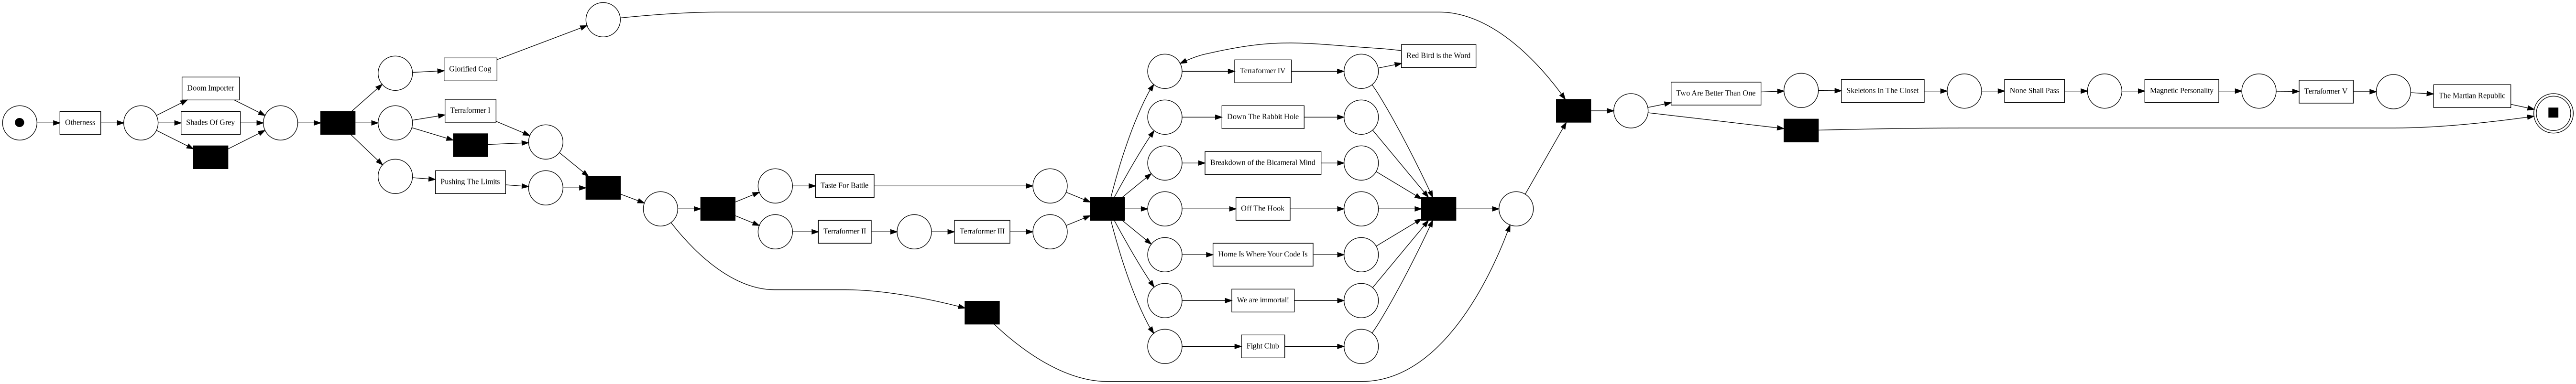

In [15]:
pm4py.view_petri_net(net, im, fm)#Iterative process model

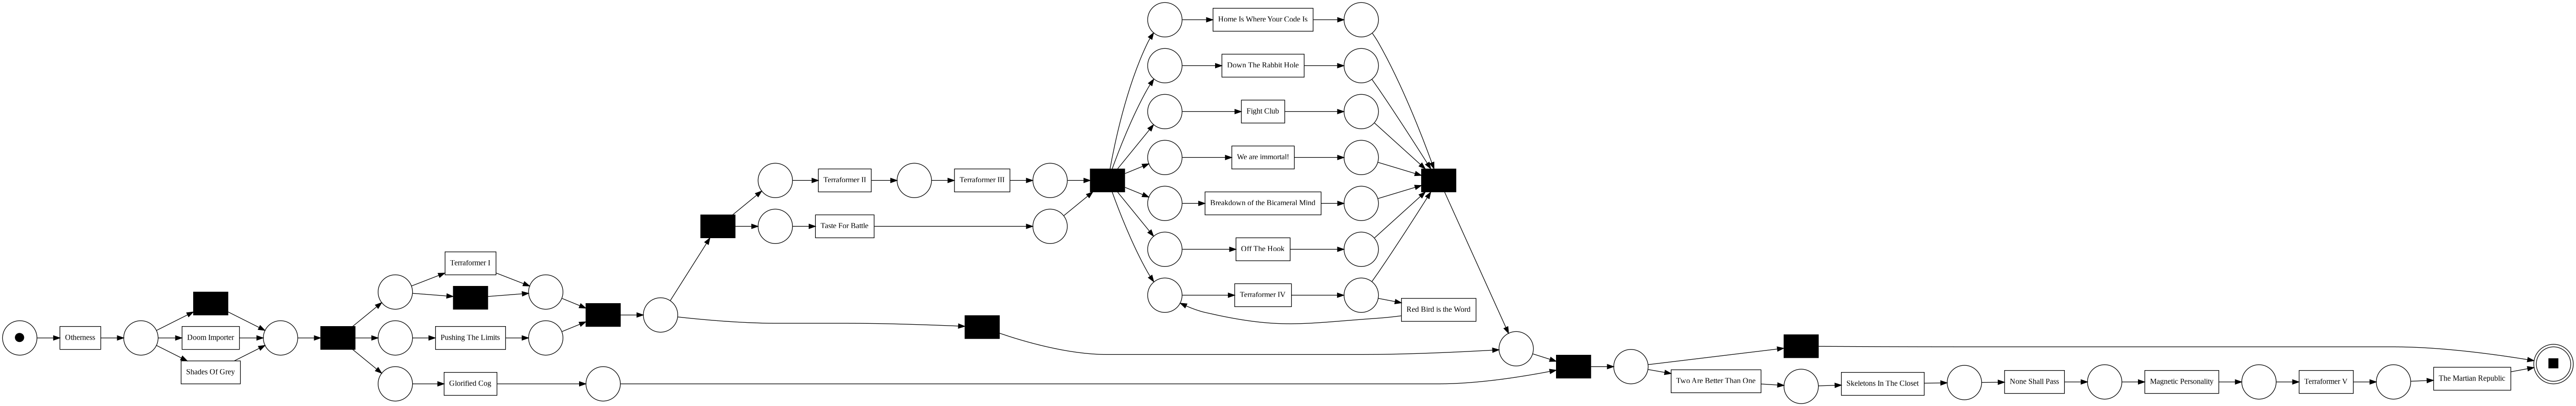

In [16]:
pm4py.view_petri_net(net_full, im_full, fm_full)#Full process model